# Capítulo 1: Patrones Armónicos (ABCD) — Detección de Formaciones Geométricas
Versión: 1.2 | Motor: Modular Dinámico v1.0 | Actualización: 2026-10-26

    "Los patrones armónicos no predicen el futuro. Identifican formaciones geométricas recurrentes en los precios que, estadísticamente, tienen mayor probabilidad de revertir en zonas específicas."
    — Scott Carney, Harmonic Trading

**Concepto clave:** Este capítulo implementa un scanner de patrones armónicos ABCD que detecta formaciones de cuatro puntos (A-B-C-D) basadas en ratios de Fibonacci. Cuando se identifica un patrón válido con tolerancia del 10%, se genera una señal de entrada en la dirección del rebote esperado, manteniendo la posición durante un período fijo (5 días) con stop-loss dinámico.

La premisa es que los mercados exhiben comportamientos fractales y que ciertas relaciones geométricas entre movimientos de precio tienden a repetirse. El patrón ABCD es el más simple de la familia armónica y sirve como base para entender la lógica de detección de formaciones.

**⚠️ Advertencia:** Los patrones armónicos son herramientas de análisis técnico con limitaciones inherentes. No garantizan resultados y deben usarse junto con gestión de riesgo estricta.

## BLOQUE 0: Configuración de la Estrategia

In [1]:
# ==============================================================================
# BLOQUE 0: CONFIGURACIÓN — PATRONES ARMÓNICOS (ABCD)
# ==============================================================================

# --- Parámetros financieros ---
CAPITAL_INICIAL = 10000
COSTE_TRANSACCION = 0.001  # 0.1% por operación
BENCHMARK = 'SPY'
RF_LIBRE = 0.02

# --- Rango temporal ---
FECHA_INICIO = None
FECHA_FIN = None

# --- Parámetros del scanner armónico ---
TOLERANCIA_PATRON = 0.10  # Tolerancia del 10% para ratios Fibonacci
HOLD_DAYS = 5  # Días que mantenemos la posición
STOP_LOSS_PCT = 0.03  # Stop-loss del 3%
TAKE_PROFIT_PCT = 0.06  # Take-profit del 6%

# --- Ratios Fibonacci válidos ---
RATIOS_BC = [0.382, 0.500, 0.618, 0.786]  # Retrocesos válidos para B-C
RATIOS_CD = [1.272, 1.414, 1.618]  # Extensiones válidas para C-D

# --- Universo de activos ---
UNIVERSO_HARMONIC = {
    'indices': {
        'SPDR_S&P_500': {'isin': 'US78462F1030', 'ticker': 'SPY'},
        'Invesco_QQQ': {'isin': 'US46090E1038', 'ticker': 'QQQ'},
    },
    'sectores': {
        'Financial_Select': {'isin': 'US81369Y5069', 'ticker': 'XLF'},
        'Technology_Select': {'isin': 'US81369Y8030', 'ticker': 'XLK'},
    }
}

NOMBRE_ESTRATEGIA = "Patrones Armónicos ABCD"

print("="*70)
print("✅ Configuración Patrones Armónicos cargada:")
print("="*70)
print(f"   • Estrategia: {NOMBRE_ESTRATEGIA}")
print(f"   • Capital inicial: €{CAPITAL_INICIAL:,.2f}")
print(f"   • Tolerancia patrón: ±{TOLERANCIA_PATRON*100:.0f}%")
print(f"   • Período de tenencia: {HOLD_DAYS} días")
print(f"   • Stop-loss: {STOP_LOSS_PCT:.1%} | Take-profit: {TAKE_PROFIT_PCT:.1%}")
print(f"   • Comisión: {COSTE_TRANSACCION*100:.2f}%")
print("="*70)

✅ Configuración Patrones Armónicos cargada:
   • Estrategia: Patrones Armónicos ABCD
   • Capital inicial: €10,000.00
   • Tolerancia patrón: ±10%
   • Período de tenencia: 5 días
   • Stop-loss: 3.0% | Take-profit: 6.0%
   • Comisión: 0.10%


## BLOQUE 1: Entorno y Importaciones 

In [2]:
# ==============================================================================
# BLOQUE 1: ENTORNO, IMPORTACIONES Y MOTOR MODULAR
# ==============================================================================

print("="*70)
print("⚠️ AVISO LEGAL: Fines exclusivamente educativos e investigativos.")
print("="*70)

import sys, os, warnings, inspect
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import argrelextrema

# Búsqueda de la carpeta 'core'
def buscar_core():
    try:
        ruta_actual = Path(__file__).parent.resolve()
    except NameError:
        ruta_actual = Path.cwd().resolve()
    
    for nivel in [ruta_actual] + list(ruta_actual.parents)[:6]:
        carpeta_core = nivel / 'core'
        if (carpeta_core.is_dir() and 
            (carpeta_core / 'gestor_proyecto.py').exists()):
            return nivel, carpeta_core
    return None, None

project_root, ruta_core = buscar_core()

if project_root is None:
    raise FileNotFoundError("❌ No se pudo encontrar la carpeta 'core'.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    from core.gestor_proyecto import GestorProyecto
    from core.gestor_datos import GestorDatos
    from core.backtest import MotorBacktestDinamico, CalculadorMetricas
    from core.informes import GeneradorInformes
    
    print("✅ Módulos importados correctamente.")
except ImportError as e:
    print(f"❌ Error importando módulos: {e}")
    raise SystemExit

# Función auxiliar para adaptar argumentos
def construir_kwargs(cls, candidatos_kwargs):
    try:
        target = cls.__init__ if inspect.isclass(cls) else cls
        firma = inspect.signature(target)
        params = firma.parameters
    except (ValueError, TypeError):
        return {}
    kwargs_filtrados = {}
    for nombre_param in params:
        if nombre_param == 'self':
            continue
        for clave, valor in candidatos_kwargs.items():
            if clave.lower().replace(' ', '') == nombre_param.lower().replace(' ', ''):
                kwargs_filtrados[nombre_param] = valor
                break
    return kwargs_filtrados

⚠️ AVISO LEGAL: Fines exclusivamente educativos e investigativos.
✅ Módulos importados correctamente.


## BLOQUE 2: GESTIÓN DEL ENTORNO DE TRABAJO

In [3]:
# ==============================================================================
# BLOQUE 2: GESTIÓN DEL ENTORNO DE TRABAJO
# ==============================================================================

print("\n" + "="*70)
print("🧹 BLOQUE 2: GESTIÓN DEL ENTORNO DE TRABAJO")
print("="*70)

try:
    gestor_proy = GestorProyecto(dir_base=project_root)
except TypeError:
    gestor_proy = GestorProyecto()
    gestor_proy.BASE_DIR = project_root

RUTA_CAP01 = Path(gestor_proy.DIRS.get("OUTPUTS", project_root / "outputs")) / "cap01_harmonicos"
RUTA_FIGURES_CAP01 = RUTA_CAP01 / "figures"
RUTA_FIGURES_CAP01.mkdir(parents=True, exist_ok=True)

print(f"✅ Entorno configurado. Base: {gestor_proy.BASE_DIR}")
print(f"📂 Directorio de figuras: {RUTA_FIGURES_CAP01}")


🧹 BLOQUE 2: GESTIÓN DEL ENTORNO DE TRABAJO
✅ Entorno configurado. Base: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales
📂 Directorio de figuras: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/cap01_harmonicos/figures


## BLOQUE 3: MENÚ DE ESTRÉS (SELECCIÓN DE PERÍODO)

In [4]:
# ==============================================================================
# BLOQUE 3: MENÚ DE ESTRÉS (SELECCIÓN DE PERÍODO)
# ==============================================================================

print("\n" + "="*70)
print("📉 BLOQUE 3: MENÚ DE ESTRÉS")
print("="*70)
print("  1. Histórico Completo (2020-Hoy)")
print("  2. Crisis Financiera (2007-2009)")
print("  3. Periodo Personalizado")

opcion = input("\nIntroduce tu opción (1-3) [1]: ").strip() or "1"

if opcion == '1':
    FECHA_INICIO, FECHA_FIN, evento = "2020-01-01", None, "Histórico Completo"
elif opcion == '2':
    FECHA_INICIO, FECHA_FIN, evento = "2007-10-01", "2009-03-31", "Crisis Financiera"
else:
    evento = "Periodo Personalizado"
    FECHA_INICIO = input("   > Fecha de inicio (YYYY-MM-DD): ").strip()
    FECHA_FIN = input("   > Fecha de fin (YYYY-MM-DD): ").strip() or None

if FECHA_FIN is None:
    from datetime import datetime
    FECHA_FIN = datetime.now().strftime("%Y-%m-%d")

print(f"\n⏳ Configurado: {evento} ({FECHA_INICIO} a {FECHA_FIN})")


📉 BLOQUE 3: MENÚ DE ESTRÉS
  1. Histórico Completo (2020-Hoy)
  2. Crisis Financiera (2007-2009)
  3. Periodo Personalizado



Introduce tu opción (1-3) [1]:  3
   > Fecha de inicio (YYYY-MM-DD):  2016-01-04
   > Fecha de fin (YYYY-MM-DD):  2026-10-15



⏳ Configurado: Periodo Personalizado (2016-01-04 a 2026-10-15)


## BLOQUE 4: MENÚ DEL GESTOR DE DATOS

In [6]:
# ==============================================================================
# BLOQUE 4: MENÚ DEL GESTOR DE DATOS (Patrones Armónicos - Autocontenido)
# ==============================================================================

print(f"\n✅ Período configurado: {evento}")
print(f"   Inicio: {FECHA_INICIO} | Fin: {FECHA_FIN}\n")

# ==============================================================================
# VARIABLES POR DEFECTO (si el Bloque 0 no se ejecutó)
# ==============================================================================
if 'UNIVERSO_HARMONIC' not in globals():
    print("⚠️  UNIVERSO_HARMONIC no definido. Usando valores por defecto...")
    UNIVERSO_HARMONIC = {
        'indices': {
            'SPDR_S&P_500': {'isin': 'US78462F1030', 'ticker': 'SPY'},
            'Invesco_QQQ': {'isin': 'US46090E1038', 'ticker': 'QQQ'},
        },
        'sectores': {
            'Financial_Select': {'isin': 'US81369Y5069', 'ticker': 'XLF'},
            'Technology_Select': {'isin': 'US81369Y8030', 'ticker': 'XLK'},
        }
    }

# ==============================================================================
# FUNCIÓN AUXILIAR: construir_kwargs (si no existe)
# ==============================================================================
if 'construir_kwargs' not in globals():
    import inspect
    def construir_kwargs(cls, candidatos_kwargs):
        try:
            target = cls.__init__ if inspect.isclass(cls) else cls
            firma = inspect.signature(target)
            params = firma.parameters
        except (ValueError, TypeError):
            return {}
        kwargs_filtrados = {}
        for nombre_param in params:
            if nombre_param == 'self':
                continue
            for clave, valor in candidatos_kwargs.items():
                if clave.lower().replace(' ', '') == nombre_param.lower().replace(' ', ''):
                    kwargs_filtrados[nombre_param] = valor
                    break
        return kwargs_filtrados

# ==============================================================================
# INICIALIZAR GESTOR DE DATOS
# ==============================================================================
print("🔄 Inicializando Gestor de Datos...")
try:
    kwargs_gestor = {
        "diccionario_datos": UNIVERSO_HARMONIC,
        "fecha_inicio": FECHA_INICIO,
        "fecha_fin": FECHA_FIN,
        "gestor_proyecto": gestor_proy
    }
    kwargs_filtrados = construir_kwargs(GestorDatos, kwargs_gestor)
    gestor = GestorDatos(**kwargs_filtrados)
    print("✅ Gestor de Datos inicializado correctamente.\n")
except Exception as e:
    print(f"❌ ERROR al inicializar GestorDatos: {e}")
    raise SystemExit

# ==============================================================================
# DESCARGA AUTOMÁTICA (sin menú interactivo)
# ==============================================================================
print("📥 Descargando/Actualizando cotizaciones desde Yahoo Finance...")
try:
    gestor.gestionar_descarga_cotizaciones()
    print("✅ Descarga completada.\n")
except Exception as e:
    print(f"⚠️  Error en la descarga: {e}")

# ==============================================================================
# GENERAR CARTERA AUTOMÁTICAMENTE (CRÍTICO: sin esto, precios_ajustados = None)
# ==============================================================================
print("🔄 Generando cartera automáticamente desde el diccionario...")
try:
    # Intentar diferentes métodos según la versión del GestorDatos
    if hasattr(gestor, '_cartera_por_defecto'):
        gestor._cartera_por_defecto()
        print("✅ Cartera generada con _cartera_por_defecto().\n")
    elif hasattr(gestor, 'generar_cartera_automatica'):
        gestor.generar_cartera_automatica()
        print("✅ Cartera generada con generar_cartera_automatica().\n")
    elif hasattr(gestor, 'preparar_datos_motor'):
        # Algunas versiones preparan directamente sin generar cartera explícita
        print("⚠️  No se encontró método específico. Intentando preparar datos directamente...\n")
    else:
        print("⚠️  No se encontró método para generar cartera automáticamente.")
        print("   Intentando preparar datos directamente...\n")
except Exception as e:
    print(f"⚠️  Error al generar cartera: {e}")

# ==============================================================================
# PREPARAR DATOS DEL MOTOR
# ==============================================================================
print("🔄 Preparando datos para el backtest...")
try:
    gestor.preparar_datos_motor()
    
    precios = gestor.precios_ajustados
    rentabilidades = gestor.rentabilidades_diarias
    
    if precios is None or precios.empty:
        raise ValueError("No se pudieron cargar los datos de precios.")
    
    # Aplanar MultiIndex si existe
    if isinstance(precios.columns, pd.MultiIndex):
        print("⚠️  Detectado MultiIndex. Aplanando columnas...")
        if 'Close' in precios.columns.get_level_values(1):
            precios = precios['Close']
        elif 'Adj Close' in precios.columns.get_level_values(1):
            precios = precios['Adj Close']
        else:
            precios = precios.iloc[:, ::6]
            precios.columns = precios.columns.get_level_values(0)
        precios.columns.name = None
        rentabilidades = precios.pct_change().dropna()
        print("✅ Datos aplanados.\n")
    
    print(f"✅ Datos cargados: {len(precios)} filas, {len(precios.columns)} activos")
    print(f"   • Período: {precios.index[0].strftime('%Y-%m-%d')} a {precios.index[-1].strftime('%Y-%m-%d')}")
    print(f"   • Activos: {list(precios.columns)}\n")
    
except Exception as e:
    print(f"\n❌ ERROR en la preparación de datos: {e}")
    print("\n💡 SOLUCIÓN ALTERNATIVA: Usa el menú interactivo")
    print("   1. Ejecuta: gestor.menu()")
    print("   2. Selecciona '1' para descargar")
    print("   3. Selecciona '6' para ejecutar estrategia")
    raise SystemExit


✅ Período configurado: Periodo Personalizado
   Inicio: 2016-01-04 | Fin: 2026-10-15

🔄 Inicializando Gestor de Datos...
✅ Gestor de Datos inicializado correctamente.

📥 Descargando/Actualizando cotizaciones desde Yahoo Finance...

🗑️ Limpiando CSVs antiguos y descargando desde Yahoo Finance...

📊 Procesando 4 activos...

   📊 SPDR_S&P_500
      ✅ Descargado con ticker: SPY

   📊 Invesco_QQQ
      ✅ Descargado con ticker: QQQ

   📊 Financial_Select
      ✅ Descargado con ticker: XLF

   📊 Technology_Select
      ✅ Descargado con ticker: XLK

 Resumen: 4 descargados, 0 omitidos
✅ Descarga completada.

🔄 Generando cartera automáticamente desde el diccionario...
📝 No hay Excel cargado. Generando cartera automática (60/40) desde el diccionario...
✅ Cartera generada con _cartera_por_defecto().

🔄 Preparando datos para el backtest...

🧼 INFORME DE LIMPIEZA DE DATOS


,Activo,ISIN,Filas,Desde,Hasta,Fuente
0,SPDR_S&P_500,US78462F1030,2711,2016-01-04,2026-10-14,CSV
1,Invesco_QQQ,US46090E1038,2711,2016-01-04,2026-10-14,CSV
2,Financial_Select,US81369Y5069,2711,2016-01-04,2026-10-14,CSV
3,Technology_Select,US81369Y8030,2711,2016-01-04,2026-10-14,CSV


✅ 4 activos alineados para el Motor Backtest.

✅ Datos cargados: 2711 filas, 4 activos
   • Período: 2016-01-04 a 2026-10-14
   • Activos: ['SPDR_S&P_500', 'Invesco_QQQ', 'Financial_Select', 'Technology_Select']



## BLOQUE 5: SCANNER DE PATRONES ARMÓNICOS Y GENERADOR DE PESOS

In [7]:
# ==============================================================================
# BLOQUE 5: SCANNER DE PATRONES ARMÓNICOS Y GENERADOR DE PESOS
# ==============================================================================

print("\n" + "="*70)
print("🔍 BLOQUE 5: DETECCIÓN DE PATRONES ABCD")
print("="*70)

if precios is None or precios.empty:
    raise ValueError("❌ No hay precios. Ejecuta Bloque 4 primero.")

# ==============================================================================
# CLASE SCANNER DE PATRONES ARMÓNICOS
# ==============================================================================
class HarmonicScanner:
    def __init__(self, precios, tol=0.10, hold_days=5):
        self.precios = precios
        self.tol = tol
        self.hold_days = hold_days
        self.ratios_bc = [0.382, 0.500, 0.618, 0.786]
        self.ratios_cd = [1.272, 1.414, 1.618]
        self.signals = pd.DataFrame(0.0, index=precios.index, columns=precios.columns)
        self.patrones_detectados = []
    
    def _find_pivots(self, series, order=3):
        """Encuentra máximos y mínimos locales."""
        max_idx = argrelextrema(series.values, np.greater, order=order)[0]
        min_idx = argrelextrema(series.values, np.less, order=order)[0]
        return min_idx, max_idx
    
    def scan_abcd(self):
        """Escanea patrones ABCD en todos los activos."""
        print(f"\n🔍 Escaneando Patrones ABCD (Hold: {self.hold_days} días, Tol: ±{self.tol*100:.0f}%)...")
        print("="*80)
        
        total_patrones = 0
        
        for col in self.precios.columns:
            series = self.precios[col].dropna()
            if len(series) < 50:
                continue
            
            min_idx, max_idx = self._find_pivots(series)
            pivots = sorted(list(min_idx) + list(max_idx))
            
            patrones_activos = 0
            
            for i in range(len(pivots) - 3):
                A, B, C, D = pivots[i], pivots[i+1], pivots[i+2], pivots[i+3]
                pA, pB, pC, pD = series.iloc[A], series.iloc[B], series.iloc[C], series.iloc[D]
                
                # Verificar estructura ABCD válida
                if not ((pB > pA and pC < pB and pD > pC) or 
                        (pB < pA and pC > pB and pD < pC)):
                    continue
                
                # Calcular ratios
                AB = abs(pB - pA)
                BC = abs(pC - pB)
                CD = abs(pD - pC)
                
                if AB == 0 or BC == 0:
                    continue
                
                retrace_bc = BC / AB
                ext_cd = CD / BC
                
                # Verificar si los ratios están dentro de la tolerancia
                is_valid_bc = any(abs(retrace_bc - r) <= self.tol for r in self.ratios_bc)
                is_valid_cd = any(abs(ext_cd - r) <= self.tol for r in self.ratios_cd)
                
                if is_valid_bc and is_valid_cd:
                    total_patrones += 1
                    patrones_activos += 1
                    
                    # Determinar dirección: Long si D < C (patrón bajista que rebota)
                    direction = 1.0 if pD < pC else -1.0
                    tipo = "LONG" if direction == 1 else "SHORT"
                    
                    fecha_d = series.index[D]
                    print(f"  ✅ {col:12s} {fecha_d.date()}: ABCD (BC={retrace_bc:.3f}, CD={ext_cd:.3f}) -> {tipo}")
                    
                    # Guardar información del patrón
                    self.patrones_detectados.append({
                        'activo': col,
                        'fecha': fecha_d,
                        'tipo': tipo,
                        'bc_ratio': retrace_bc,
                        'cd_ratio': ext_cd,
                        'precio_entrada': pD,
                        'direccion': direction
                    })
                    
                    # Aplicar señal: Entramos el día siguiente a D y mantenemos hold_days
                    start_pos = self.precios.index.get_loc(series.index[D])
                    col_idx = self.precios.columns.get_loc(col)
                    
                    for d in range(1, self.hold_days + 1):
                        if start_pos + d < len(self.signals):
                            self.signals.iloc[start_pos + d, col_idx] = direction
            
            if patrones_activos > 0:
                print(f"  📊 Total patrones en {col}: {patrones_activos}")
        
        print("\n" + "="*80)
        print(f"📈 RESUMEN: {total_patrones} patrones ABCD detectados en total")
        print("="*80)
        
        return self.signals, self.patrones_detectados

# ==============================================================================
# EJECUTAR SCANNER
# ==============================================================================
scanner = HarmonicScanner(
    precios=precios,
    tol=TOLERANCIA_PATRON,
    hold_days=HOLD_DAYS
)
señales, patrones = scanner.scan_abcd()

print(f"\n✅ Scanner completado:")
print(f"   • Patrones detectados: {len(patrones)}")
print(f"   • Señales generadas: {(señales != 0).sum().sum()}")

# ==============================================================================
# GENERADOR DE PESOS (PATRÓN CLOSURE)
# ==============================================================================
print("\n" + "="*70)
print("️  GENERADOR DE PESOS ARMÓNICOS")
print("="*70)

def crear_generador_pesos_harmonic(señales_df, benchmark_col, stop_loss, take_profit):
    """Fábrica del generador de pesos para el motor dinámico."""
    
    def generador_pesos(fecha_actual, precios_hist, rent_hist, estado):
        activos = list(precios_hist.columns)
        pesos = {a: 0.0 for a in activos}
        
        if 'posiciones_activas' not in estado:
            estado['posiciones_activas'] = {}
        
        # Obtener señales activas en esta fecha
        if fecha_actual in señales_df.index:
            señales_activas = señales_df.loc[fecha_actual]
            
            for activo in activos:
                if activo == benchmark_col:
                    continue
                
                señal = señales_activas.get(activo, 0.0)
                
                if señal != 0.0 and activo not in estado['posiciones_activas']:
                    # Nueva entrada
                    precio_actual = precios_hist[activo].iloc[-1]
                    estado['posiciones_activas'][activo] = {
                        'fecha_entrada': fecha_actual,
                        'precio_entrada': precio_actual,
                        'direccion': señal,
                        'dias_en_posicion': 0
                    }
        
        # Gestionar posiciones existentes
        posiciones_a_cerrar = []
        
        for activo, info in estado['posiciones_activas'].items():
            if activo not in precios_hist.columns:
                posiciones_a_cerrar.append(activo)
                continue
            
            precio_actual = precios_hist[activo].iloc[-1]
            precio_entrada = info['precio_entrada']
            direccion = info['direccion']
            
            # Calcular rentabilidad
            rentabilidad = (precio_actual / precio_entrada - 1) * direccion
            
            # Incrementar días en posición
            info['dias_en_posicion'] += 1
            
            # Criterios de salida
            if rentabilidad <= -stop_loss:
                posiciones_a_cerrar.append(activo)
                print(f"  🛑 Stop-loss: {activo} @ {fecha_actual.date()} ({rentabilidad:.2%})")
            elif rentabilidad >= take_profit:
                posiciones_a_cerrar.append(activo)
                print(f"  ✅ Take-profit: {activo} @ {fecha_actual.date()} ({rentabilidad:.2%})")
            elif info['dias_en_posicion'] >= HOLD_DAYS:
                posiciones_a_cerrar.append(activo)
                print(f"  ⏰ Time exit: {activo} @ {fecha_actual.date()} ({rentabilidad:.2%})")
        
        # Cerrar posiciones
        for activo in posiciones_a_cerrar:
            del estado['posiciones_activas'][activo]
        
        # Asignar pesos (equiponderados entre activos con posición)
        n_posiciones = len(estado['posiciones_activas'])
        if n_posiciones > 0:
            peso_por_activo = 0.95 / n_posiciones  # 95% invertido, 5% cash
            for activo in estado['posiciones_activas']:
                pesos[activo] = peso_por_activo * estado['posiciones_activas'][activo]['direccion']
        
        # Resto en benchmark (cash proxy)
        if benchmark_col in activos:
            pesos[benchmark_col] = max(0.0, 1.0 - sum(abs(p) for p in pesos.values()))
        
        return pesos, estado
    
    return generador_pesos

generador_pesos_harmonic = crear_generador_pesos_harmonic(
    señales,
    'SPDR_S&P_500',
    STOP_LOSS_PCT,
    TAKE_PROFIT_PCT
)

print("\n✅ Generador de pesos configurado.")
print(f"   • Stop-loss: {STOP_LOSS_PCT:.1%}")
print(f"   • Take-profit: {TAKE_PROFIT_PCT:.1%}")
print(f"   • Máx. días en posición: {HOLD_DAYS}")
print("="*70)


🔍 BLOQUE 5: DETECCIÓN DE PATRONES ABCD

🔍 Escaneando Patrones ABCD (Hold: 5 días, Tol: ±10%)...
  ✅ SPDR_S&P_500 2016-05-19: ABCD (BC=0.547, CD=1.277) -> LONG
  ✅ SPDR_S&P_500 2017-08-18: ABCD (BC=0.774, CD=1.330) -> LONG
  ✅ SPDR_S&P_500 2017-10-27: ABCD (BC=0.743, CD=1.330) -> SHORT
  ✅ SPDR_S&P_500 2018-07-18: ABCD (BC=0.844, CD=1.407) -> SHORT
  ✅ SPDR_S&P_500 2018-09-20: ABCD (BC=0.400, CD=1.541) -> SHORT
  ✅ SPDR_S&P_500 2019-04-08: ABCD (BC=0.496, CD=1.714) -> SHORT
  ✅ SPDR_S&P_500 2020-04-29: ABCD (BC=0.336, CD=1.483) -> SHORT
  ✅ SPDR_S&P_500 2020-12-17: ABCD (BC=0.679, CD=1.376) -> SHORT
  ✅ SPDR_S&P_500 2021-01-25: ABCD (BC=0.446, CD=1.563) -> SHORT
  ✅ SPDR_S&P_500 2021-04-29: ABCD (BC=0.876, CD=1.550) -> SHORT
  ✅ SPDR_S&P_500 2021-05-07: ABCD (BC=0.563, CD=1.464) -> SHORT
  ✅ SPDR_S&P_500 2021-06-03: ABCD (BC=0.512, CD=1.383) -> SHORT
  ✅ SPDR_S&P_500 2021-10-04: ABCD (BC=0.802, CD=1.485) -> LONG
  ✅ SPDR_S&P_500 2022-01-03: ABCD (BC=0.700, CD=1.611) -> SHORT
  ✅ SPDR_S

## BLOQUE 6: EJECUCIÓN DEL BACKTEST

In [8]:
# ==============================================================================
# BLOQUE 6: EJECUCIÓN DEL BACKTEST
# ==============================================================================

print("\n" + "="*70)
print("⏳ EJECUTANDO BACKTEST PATRONES ARMÓNICOS")
print("="*70)

# Variables por defecto (si el Bloque 0 no se ejecutó)
if 'COSTE_TRANSACCION' not in globals():
    COSTE_TRANSACCION = 0.001
if 'CAPITAL_INICIAL' not in globals():
    CAPITAL_INICIAL = 10000.0
if 'BENCHMARK' not in globals():
    BENCHMARK = 'SPY'

motor_harmonic = MotorBacktestDinamico(
    precios=precios,
    rentabilidades=rentabilidades,
    generador_pesos=generador_pesos_harmonic,
    frecuencia_decision='D',  # Diario para capturar señales de patrones
    coste_transaccion=COSTE_TRANSACCION,
    benchmark_ticker=BENCHMARK,
    permitir_short=True,  # Los patrones pueden ser long o short
    max_short_porcentaje=0.50
)

serie_patrimonio_harmonic = motor_harmonic.ejecutar_backtest(
    capital_inicial=CAPITAL_INICIAL,
    estado_inicial={}
)

if serie_patrimonio_harmonic is not None:
    print(f"\n✅ Backtest completado.")
    print(f"   • Patrimonio final: {serie_patrimonio_harmonic.iloc[-1]:,.2f} €")
    print(f"   • Rentabilidad total: {((serie_patrimonio_harmonic.iloc[-1] / CAPITAL_INICIAL) - 1) * 100:.2f}%")
    print(f"   • Rebalanceos: {len(motor_harmonic.log_transacciones)}")
else:
    print("❌ El backtest falló.")


⏳ EJECUTANDO BACKTEST PATRONES ARMÓNICOS
  ⏰ Time exit: Financial_Select @ 2016-05-24 (1.40%)
  ⏰ Time exit: Technology_Select @ 2016-08-31 (0.30%)
  ⏰ Time exit: Invesco_QQQ @ 2016-09-06 (0.15%)
  ⏰ Time exit: Financial_Select @ 2016-10-06 (2.94%)
  ⏰ Time exit: Technology_Select @ 2016-10-17 (1.21%)
  ⏰ Time exit: Invesco_QQQ @ 2016-11-30 (-0.03%)
  ⏰ Time exit: Technology_Select @ 2016-12-23 (-0.68%)
  ⏰ Time exit: Invesco_QQQ @ 2017-07-11 (1.81%)
  ⏰ Time exit: Financial_Select @ 2017-08-28 (1.06%)
  ⏰ Time exit: Technology_Select @ 2017-09-19 (-0.02%)
  ⏰ Time exit: Financial_Select @ 2017-11-09 (2.38%)
  ⏰ Time exit: Technology_Select @ 2017-12-05 (3.43%)
  ⏰ Time exit: Technology_Select @ 2018-05-17 (0.66%)
  ⏰ Time exit: Invesco_QQQ @ 2018-05-21 (1.35%)
  ⏰ Time exit: Financial_Select @ 2018-07-05 (0.46%)
  ⏰ Time exit: Technology_Select @ 2018-11-05 (2.69%)
  ⏰ Time exit: Technology_Select @ 2018-11-14 (5.16%)
  ⏰ Time exit: Invesco_QQQ @ 2019-02-28 (-1.15%)
  ⏰ Time exit: In

## BLOQUE 7: MÉTRICAS E INFORMES

In [9]:
# ==============================================================================
# BLOQUE 7: MÉTRICAS E INFORMES
# ==============================================================================

print("\n" + "="*70)
print("📊 MÉTRICAS: PATRONES ARMÓNICOS vs. BUY & HOLD")
print("="*70)

# Variables por defecto
if 'RF_LIBRE' not in globals():
    RF_LIBRE = 0.02

auditor = CalculadorMetricas(
    serie_patrimonio=motor_harmonic.serie_patrimonio,
    serie_buy_hold=motor_harmonic.serie_buy_hold,
    serie_benchmark=motor_harmonic.serie_benchmark
)
metricas_harmonic, metricas_bh = auditor.calcular_todas_las_metricas(rf=RF_LIBRE)

print(f"\n{'Métrica':<20}| {'Patrones ABCD':<20}| {'Buy & Hold (SPY)':<20}")
print("-" * 65)
for key in metricas_harmonic.keys():
    val_harmonic = metricas_harmonic[key]
    val_bh = metricas_bh.get(key, 0)
    if key in ['CAGR', 'Volatilidad', 'Max Drawdown']:
        print(f"{key:<20}| {val_harmonic:>19.2%}| {val_bh:>19.2%}")
    else:
        print(f"{key:<20}| {val_harmonic:>19.2f}| {val_bh:>19.2f}")

print("-" * 65)

# Diagnóstico
print("\n🩺 DIAGNÓSTICO:")
print("   • " + auditor.diagnosticar().replace('\n', '\n   • '))

# Nota pedagógica
print("\n" + "="*70)
print("️  NOTA PEDAGÓGICA: LIMITACIONES DE LOS PATRONES ARMÓNICOS")
print("="*70)
print("""
️  LOS PATRONES ARMÓNICOS NO SON UNA BALA DE PLATA:

1. Los ratios Fibonacci son aproximaciones, no leyes físicas.
2. La tolerancia del 10% genera falsos positivos.
3. Los patrones no consideran el contexto fundamental del mercado.
4. El backtest asume ejecución perfecta en el punto D (look-ahead bias parcial).
5. Los costes de transacción y el slippage real pueden erosionar el alpha.

El valor pedagógico está en entender:
- Cómo detectar formaciones geométricas recurrentes.
- La importancia de la gestión de riesgo (stop-loss, take-profit, time exit).
- Las limitaciones del análisis técnico puro.
""")


📊 MÉTRICAS: PATRONES ARMÓNICOS vs. BUY & HOLD

Métrica             | Patrones ABCD       | Buy & Hold (SPY)    
-----------------------------------------------------------------
CAGR                |              21.26%|              15.10%
Volatilidad         |              18.24%|              17.69%
Sharpe              |                1.06|                0.74
Sortino             |                1.02|                0.70
Max Drawdown        |             -33.72%|             -33.72%
VaR 95%             |             1344.71|              754.15
Alpha               |                0.00|                0.00
Beta                |                0.00|                0.00
R2                  |                0.00|                0.00
Tracking Error      |                0.00|                0.00
-----------------------------------------------------------------

🩺 DIAGNÓSTICO:
   • ✅ Ratio de Sharpe excelente (1.06).
   •   🔴 Riesgo de caída elevado (Max DD: 33.7%).

️  NOTA PEDAGÓGIC

## BLOQUE 8: VISUALIZACIÓN


📈 BLOQUE 8: GENERACIÓN DE GRÁFICOS
✅ Gráfico guardado en: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/cap01_harmonicos/figures/harmonicos_2016_2026.png


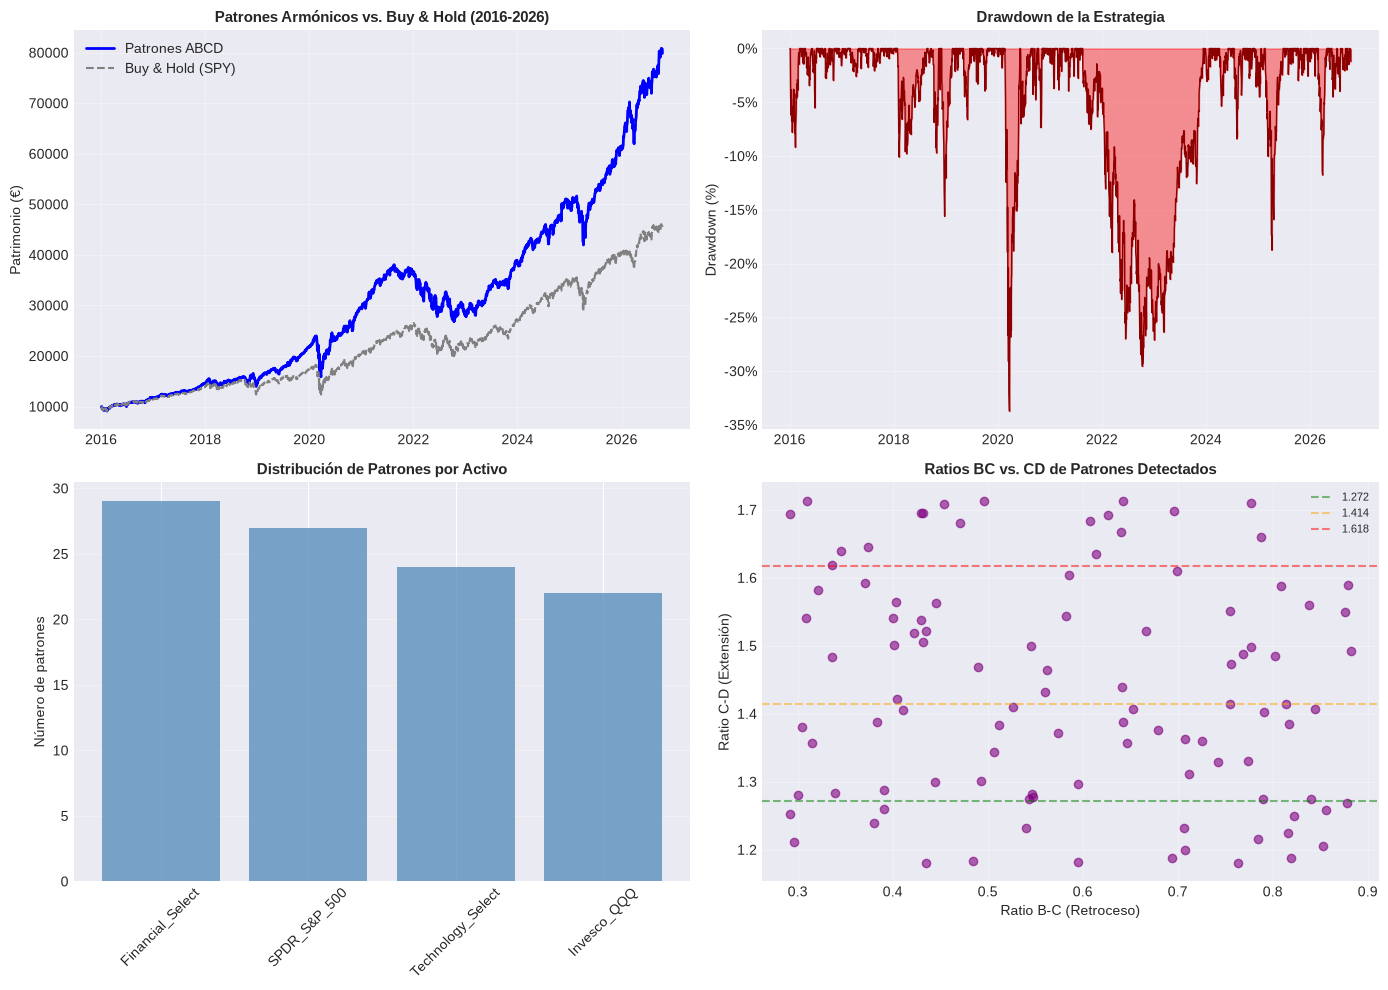

In [10]:
# ==============================================================================
# BLOQUE 8: VISUALIZACIÓN
# ==============================================================================

print("\n" + "="*70)
print("📈 BLOQUE 8: GENERACIÓN DE GRÁFICOS")
print("="*70)

try:
    plt.style.use('seaborn-v0_8-darkgrid')
except:
    plt.style.use('seaborn-darkgrid')

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

fecha_ini = str(FECHA_INICIO)[:4] if FECHA_INICIO else "2020"
fecha_fin = str(FECHA_FIN)[:4] if FECHA_FIN else "Hoy"

# 1.1 Equity Curve
axes[0, 0].plot(serie_patrimonio_harmonic.index, serie_patrimonio_harmonic, 
                label='Patrones ABCD', color='blue', lw=2)
axes[0, 0].plot(motor_harmonic.serie_buy_hold.index, motor_harmonic.serie_buy_hold, 
                label='Buy & Hold (SPY)', color='gray', ls='--', lw=1.5)
axes[0, 0].set_title(f'Patrones Armónicos vs. Buy & Hold ({fecha_ini}-{fecha_fin})', 
                     fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel('Patrimonio (€)')
axes[0, 0].legend(loc='upper left')
axes[0, 0].grid(True, alpha=0.3)

# 1.2 Drawdown
drawdown = (serie_patrimonio_harmonic / serie_patrimonio_harmonic.cummax()) - 1
axes[0, 1].fill_between(drawdown.index, drawdown, 0, color='red', alpha=0.4)
axes[0, 1].plot(drawdown.index, drawdown, color='darkred', lw=1)
axes[0, 1].set_title('Drawdown de la Estrategia', fontsize=11, fontweight='bold')
axes[0, 1].set_ylabel('Drawdown (%)')
axes[0, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[0, 1].grid(True, alpha=0.3)

# 1.3 Distribución de patrones por activo
if patrones:
    df_patrones = pd.DataFrame(patrones)
    distribucion = df_patrones['activo'].value_counts()
    axes[1, 0].bar(distribucion.index, distribucion.values, color='steelblue', alpha=0.7)
    axes[1, 0].set_title('Distribución de Patrones por Activo', fontsize=11, fontweight='bold')
    axes[1, 0].set_ylabel('Número de patrones')
    axes[1, 0].tick_params(axis='x', rotation=45)
    axes[1, 0].grid(True, alpha=0.3, axis='y')

# 1.4 Ratios de los patrones detectados
if patrones:
    df_patrones = pd.DataFrame(patrones)
    axes[1, 1].scatter(df_patrones['bc_ratio'], df_patrones['cd_ratio'], 
                       alpha=0.6, color='purple')
    axes[1, 1].set_title('Ratios BC vs. CD de Patrones Detectados', fontsize=11, fontweight='bold')
    axes[1, 1].set_xlabel('Ratio B-C (Retroceso)')
    axes[1, 1].set_ylabel('Ratio C-D (Extensión)')
    axes[1, 1].axhline(y=1.272, color='green', ls='--', alpha=0.5, label='1.272')
    axes[1, 1].axhline(y=1.414, color='orange', ls='--', alpha=0.5, label='1.414')
    axes[1, 1].axhline(y=1.618, color='red', ls='--', alpha=0.5, label='1.618')
    axes[1, 1].legend(fontsize=8)
    axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
ruta_grafico = RUTA_FIGURES_CAP01 / f"harmonicos_{fecha_ini}_{fecha_fin}.png"
fig.savefig(ruta_grafico, dpi=150, bbox_inches='tight')
print(f"✅ Gráfico guardado en: {ruta_grafico}")
plt.show()
plt.close(fig)

## BLOQUE 9: ANÁLISIS DE SEÑALES Y EFECTIVIDAD

In [11]:
# ==============================================================================
# BLOQUE 9: ANÁLISIS DE SEÑALES Y EFECTIVIDAD
# ==============================================================================

print("\n" + "="*70)
print("🔍 BLOQUE 9: ANÁLISIS DE SEÑALES Y EFECTIVIDAD")
print("="*70)

# ==============================================================================
# 1. ANÁLISIS DE PATRONES DETECTADOS
# ==============================================================================
if patrones:
    df_patrones = pd.DataFrame(patrones)
    
    print(f"\n📊 ESTADÍSTICAS DE PATRONES")
    print("-" * 70)
    print(f"   • Total de patrones detectados: {len(df_patrones)}")
    print(f"   • Activos con patrones: {df_patrones['activo'].nunique()}")
    print(f"   • Patrones LONG: {(df_patrones['tipo'] == 'LONG').sum()}")
    print(f"   • Patrones SHORT: {(df_patrones['tipo'] == 'SHORT').sum()}")
    
    # Distribución de ratios
    print(f"\n📋 DISTRIBUCIÓN DE RATIOS:")
    print(f"   • Ratio B-C medio: {df_patrones['bc_ratio'].mean():.3f} ± {df_patrones['bc_ratio'].std():.3f}")
    print(f"   • Ratio C-D medio: {df_patrones['cd_ratio'].mean():.3f} ± {df_patrones['cd_ratio'].std():.3f}")
    
    # Distribución por activo
    print(f"\n DISTRIBUCIÓN POR ACTIVO:")
    for activo, count in df_patrones['activo'].value_counts().items():
        print(f"   • {activo}: {count} patrones ({count/len(df_patrones)*100:.1f}%)")
    
    # Distribución temporal
    print(f"\n📅 DISTRIBUCIÓN TEMPORAL:")
    df_patrones['año'] = df_patrones['fecha'].dt.year
    for año, count in df_patrones.groupby('año').size().items():
        print(f"   • {año}: {count} patrones")
else:
    print("\n⚠️ No se detectaron patrones.")

# ==============================================================================
# 2. ANÁLISIS DE REBALANCEOS
# ==============================================================================
if len(motor_harmonic.log_transacciones) > 0:
    print(f"\n📊 ESTADÍSTICAS DE REBALANCEOS ({len(motor_harmonic.log_transacciones)} operaciones)")
    print("-" * 70)
    
    df_ops = pd.DataFrame(motor_harmonic.log_transacciones)
    
    if 'Rotacion %' in df_ops.columns:
        rotacion_media = df_ops['Rotacion %'].mean()
        print(f"   • Rotación media por rebalanceo: {rotacion_media*100:.2f}%")
    
    if 'Coste (€)' in df_ops.columns:
        coste_total = df_ops['Coste (€)'].sum()
        coste_medio = df_ops['Coste (€)'].mean()
        print(f"   • Coste total de transacciones: €{coste_total:,.2f}")
        print(f"   • Coste medio por rebalanceo: €{coste_medio:,.2f}")
        print(f"   • Coste como % del capital inicial: {coste_total/CAPITAL_INICIAL*100:.2f}%")
    
    if 'Patrimonio (€)' in df_ops.columns:
        patrimonio_final = df_ops['Patrimonio (€)'].iloc[-1]
        print(f"   • Patrimonio final: €{patrimonio_final:,.2f}")
    
    # Frecuencia de rebalanceos
    if 'Fecha' in df_ops.columns:
        df_ops['Fecha'] = pd.to_datetime(df_ops['Fecha'])
        dias_totales = (df_ops['Fecha'].max() - df_ops['Fecha'].min()).days
        rebalanceos_por_año = len(df_ops) / (dias_totales / 365.25) if dias_totales > 0 else 0
        print(f"   • Frecuencia de rebalanceos: {rebalanceos_por_año:.1f} por año")
    
    print("-" * 70)
    
    # Últimos 10 rebalanceos
    print(f"\n📋 ÚLTIMOS 10 REBALANCEOS:")
    df_log = df_ops.tail(10)
    cols_mostrar = [c for c in ['Fecha', 'Rotacion %', 'Coste (€)', 'Patrimonio (€)'] if c in df_log.columns]
    print(df_log[cols_mostrar].to_string(index=False))
else:
    print("\n⚠️ No hay rebalanceos registrados.")

# ==============================================================================
# 3. FUNNEL DE SEÑALES
# ==============================================================================
if patrones:
    print(f"\n🧪 ANÁLISIS DE FILTRADO DE SEÑALES")
    print("-" * 70)
    
    # Patrones totales vs patrones válidos (dentro de tolerancia)
    n_totales = len(patrones)
    print(f"   • Patrones totales detectados: {n_totales}")
    print(f"   • Tolerancia aplicada: ±{TOLERANCIA_PATRON*100:.0f}%")
    
    # Patrones por tipo
    n_long = sum(1 for p in patrones if p['tipo'] == 'LONG')
    n_short = sum(1 for p in patrones if p['tipo'] == 'SHORT')
    print(f"   • Patrones LONG: {n_long} ({n_long/n_totales*100:.1f}%)")
    print(f"   • Patrones SHORT: {n_short} ({n_short/n_totales*100:.1f}%)")
    
    print("-" * 70)

print("\n" + "="*70)
print("💡 INTERPRETACIÓN:")
print("   • Muchos patrones → Alta actividad de formaciones geométricas.")
print("   • Pocos patrones → Tolerancia demasiado estricta o período sin formaciones.")
print("   • Muchos rebalanceos → Alta frecuencia de rotación de cartera.")
print("   • Pocos rebalanceos → Estrategia selectiva o señales escasas.")
print("   • Coste total alto → Puede erosionar el alpha de la estrategia.")
print("="*70)


🔍 BLOQUE 9: ANÁLISIS DE SEÑALES Y EFECTIVIDAD

📊 ESTADÍSTICAS DE PATRONES
----------------------------------------------------------------------
   • Total de patrones detectados: 102
   • Activos con patrones: 4
   • Patrones LONG: 37
   • Patrones SHORT: 65

📋 DISTRIBUCIÓN DE RATIOS:
   • Ratio B-C medio: 0.585 ± 0.181
   • Ratio C-D medio: 1.437 ± 0.163

 DISTRIBUCIÓN POR ACTIVO:
   • Financial_Select: 29 patrones (28.4%)
   • SPDR_S&P_500: 27 patrones (26.5%)
   • Technology_Select: 24 patrones (23.5%)
   • Invesco_QQQ: 22 patrones (21.6%)

📅 DISTRIBUCIÓN TEMPORAL:
   • 2016: 8 patrones
   • 2017: 7 patrones
   • 2018: 7 patrones
   • 2019: 5 patrones
   • 2020: 15 patrones
   • 2021: 13 patrones
   • 2022: 9 patrones
   • 2023: 9 patrones
   • 2024: 7 patrones
   • 2025: 11 patrones
   • 2026: 11 patrones

📊 ESTADÍSTICAS DE REBALANCEOS (166 operaciones)
----------------------------------------------------------------------
   • Rotación media por rebalanceo: 86.20%
   • Coste tot

## BLOQUE 9b: SENSIBILIDAD A COSTES Y FRECUENCIA

In [12]:
# ==============================================================================
# BLOQUE 9b: SENSIBILIDAD A COSTES Y FRECUENCIA
# ==============================================================================

print("\n" + "="*70)
print("️ BLOQUE 9b: SENSIBILIDAD A COSTES Y FRECUENCIA")
print("="*70)

rf_d = (1 + RF_LIBRE) ** (1 / 252) - 1
filas = []

print("\n🔄 Ejecutando backtests de sensibilidad...")

# Variamos el coste de transacción y la tolerancia del patrón
for coste in (0.0, COSTE_TRANSACCION, 0.003):
    for tol in (0.05, 0.10, 0.15):
        try:
            # Recrear scanner con nueva tolerancia
            scanner_test = HarmonicScanner(
                precios=precios,
                tol=tol,
                hold_days=HOLD_DAYS
            )
            señales_test, _ = scanner_test.scan_abcd()
            
            # Recrear generador
            gen_test = crear_generador_pesos_harmonic(
                señales_test,
                'SPDR_S&P_500',
                STOP_LOSS_PCT,
                TAKE_PROFIT_PCT
            )
            
            # Ejecutar backtest
            motor_test = MotorBacktestDinamico(
                precios=precios,
                rentabilidades=rentabilidades,
                generador_pesos=gen_test,
                frecuencia_decision='D',
                coste_transaccion=coste,
                benchmark_ticker=BENCHMARK,
                permitir_short=True,
                max_short_porcentaje=0.50
            )
            serie_test = motor_test.ejecutar_backtest(
                capital_inicial=CAPITAL_INICIAL,
                estado_inicial={}
            )
            
            if serie_test is not None and not serie_test.empty:
                r = serie_test.pct_change().dropna()
                n_days = len(r)
                
                # CAGR
                total_ret = (serie_test.iloc[-1] / serie_test.iloc[0])
                years = n_days / 252
                cagr = total_ret ** (1 / years) - 1 if years > 0 else 0
                
                # Sharpe
                sharpe = (r.mean() - rf_d) / r.std() * np.sqrt(252) if r.std() > 0 else 0
                
                # Max Drawdown
                cummax = serie_test.cummax()
                dd = (serie_test - cummax) / cummax
                max_dd = dd.min()
                
                filas.append({
                    "Coste_%": coste * 100,
                    "Tolerancia_%": tol * 100,
                    "CAGR_%": cagr * 100,
                    "Sharpe": sharpe,
                    "MaxDD_%": max_dd * 100,
                    "N_ops": len(motor_test.log_transacciones),
                })
        except Exception as e:
            print(f"⚠️ Error con coste={coste}, tol={tol}: {e}")

sens = pd.DataFrame(filas)

if not sens.empty:
    print("\n📊 TABLA DE SENSIBILIDAD (CAGR anualizado):")
    print(sens.to_string(index=False))
    
    # Análisis de robustez
    cagr_base = sens.loc[(sens["Coste_%"]==COSTE_TRANSACCION*100) & (sens["Tolerancia_%"]==TOLERANCIA_PATRON*100), "CAGR_%"].values
    if len(cagr_base):
        cagr_base = cagr_base[0]
        degradacion = sens["CAGR_%"].min() - cagr_base
        print(f"\n DEGRADACIÓN RESPECTO AL CASO BASE (CAGR={cagr_base:.2f}%):")
        print(f"   • Peor caso: {degradacion:+.2f}%")
        print(f"   • Mejor caso: {sens['CAGR_%'].max() - cagr_base:+.2f}%")
        if degradacion > -cagr_base * 0.5:
            print("   ✅ El sistema es robusto a variaciones de costes y tolerancia.")
        else:
            print("   ⚠️ Sensible a costes y tolerancia del patrón.")
else:
    print("❌ No se pudieron generar resultados de sensibilidad.")

print("\n💡 INTERPRETACIÓN:")
print("   • Si el CAGR se mantiene positivo con coste=0.3%, la estrategia es viable.")
print("   • Una tolerancia más amplia (15%) captura más patrones pero con más ruido.")
print("   • Una tolerancia más estricta (5%) filtra mejor pero puede perder oportunidades.")
print("="*70)


️ BLOQUE 9b: SENSIBILIDAD A COSTES Y FRECUENCIA

🔄 Ejecutando backtests de sensibilidad...

🔍 Escaneando Patrones ABCD (Hold: 5 días, Tol: ±5%)...
  ✅ SPDR_S&P_500 2016-05-19: ABCD (BC=0.547, CD=1.277) -> LONG
  ✅ SPDR_S&P_500 2021-06-03: ABCD (BC=0.512, CD=1.383) -> SHORT
  ✅ SPDR_S&P_500 2023-07-03: ABCD (BC=0.595, CD=1.297) -> SHORT
  ✅ SPDR_S&P_500 2025-01-10: ABCD (BC=0.642, CD=1.387) -> LONG
  ✅ SPDR_S&P_500 2025-02-03: ABCD (BC=0.546, CD=1.282) -> LONG
  ✅ SPDR_S&P_500 2025-08-28: ABCD (BC=0.405, CD=1.422) -> SHORT
  📊 Total patrones en SPDR_S&P_500: 6
  ✅ Invesco_QQQ  2016-11-22: ABCD (BC=0.755, CD=1.414) -> SHORT
  ✅ Invesco_QQQ  2017-07-03: ABCD (BC=0.614, CD=1.634) -> LONG
  ✅ Invesco_QQQ  2018-05-14: ABCD (BC=0.813, CD=1.415) -> SHORT
  ✅ Invesco_QQQ  2020-06-23: ABCD (BC=0.823, CD=1.250) -> SHORT
  ✅ Invesco_QQQ  2020-12-17: ABCD (BC=0.384, CD=1.388) -> SHORT
  ✅ Invesco_QQQ  2021-07-26: ABCD (BC=0.374, CD=1.645) -> SHORT
  ✅ Invesco_QQQ  2021-11-19: ABCD (BC=0.371, CD=1.

## BLOQUE 9c: TEST PLACEBO DE TIMING


🎲 BLOQUE 9c: TEST PLACEBO DE TIMING

🎯 RESULTADO DEL TEST PLACEBO:
   • Simulaciones: 2000
   • Patrones reales: 102
   • Semilla: 42

   • Rentab. media por patrón:
        real  : +0.86%
        azar  : -0.01%  (p5=-0.46%, p95=+0.46%)
        p-valor: 0.003

   • Suma de log-rentabilidades:
        real  : +0.850
        azar  : -0.047
        p-valor: 0.002

 VEREDICTO: ✅ El timing de los patrones SÍ parece aportar (p<0.05).


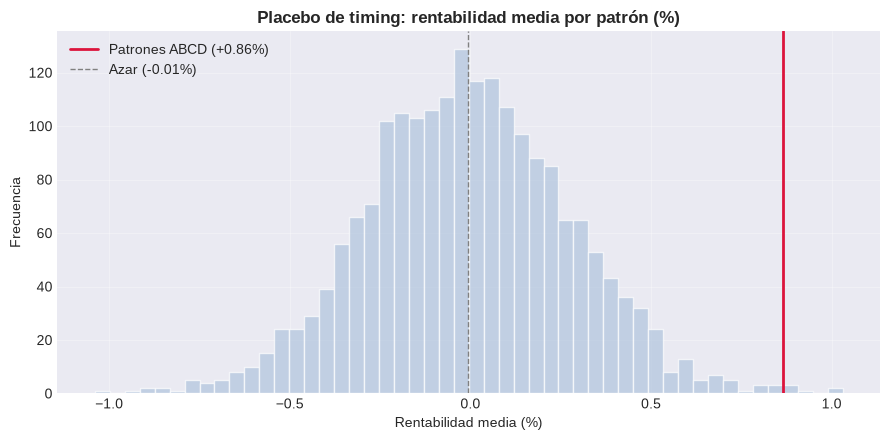


💡 INTERPRETACIÓN:
   • Si p < 0.05: las fechas de los patrones tienen información predictiva real.
   • Si p >= 0.05: el rendimiento observado podría deberse al azar.
   • Este test es más honesto que el backtest porque rompe la dependencia temporal.


In [13]:
# ==============================================================================
# BLOQUE 9c: TEST PLACEBO DE TIMING
# ==============================================================================

print("\n" + "="*70)
print("🎲 BLOQUE 9c: TEST PLACEBO DE TIMING")
print("="*70)

N_SIM = 2000
SEMILLA = 42

# ==============================================================================
# FUNCIÓN PLACEBO: ¿Las fechas de los patrones aportan algo vs. el azar?
# ==============================================================================
def placebo_harmonic(df_patrones, precios_df, hold_days, n_sim=N_SIM, semilla=SEMILLA):
    """
    H0: las fechas de los patrones no aportan nada.
    Se conservan el nº de patrones y sus duraciones (hold_days)
    y se colocan al azar en el período.
    """
    if df_patrones is None or len(df_patrones) < 5:
        return None
    
    rng = np.random.default_rng(semilla)
    
    # 1. Calcular rendimientos reales de cada patrón
    rendimientos_reales = []
    for _, row in df_patrones.iterrows():
        activo = row['activo']
        fecha_entrada = pd.Timestamp(row['fecha']).normalize()
        direccion = row['direccion']
        
        if activo not in precios_df.columns:
            continue
        
        idx_ini = precios_df.index.searchsorted(fecha_entrada, side='right')
        idx_fin = idx_ini + hold_days
        
        if idx_ini < len(precios_df) and idx_fin < len(precios_df):
            p_ini = precios_df[activo].iloc[idx_ini]
            p_fin = precios_df[activo].iloc[idx_fin]
            if p_ini > 0:
                rend = (p_fin / p_ini - 1) * direccion
                rendimientos_reales.append(rend)
    
    if len(rendimientos_reales) < 5:
        return None
    
    real = {
        "media": np.mean(rendimientos_reales),
        "suma_log": np.sum(np.log1p(np.array(rendimientos_reales))),
        "n": len(rendimientos_reales)
    }
    
    # 2. Simulaciones aleatorias
    sim_media = np.zeros(n_sim)
    sim_suma = np.zeros(n_sim)
    
    fechas_disponibles = precios_df.index
    activos_disponibles = list(precios_df.columns)
    
    for s in range(n_sim):
        rends_sim = []
        
        # Colocar el mismo número de patrones en fechas aleatorias
        for _ in range(real["n"]):
            idx_aleatorio = rng.integers(0, len(fechas_disponibles) - hold_days)
            fecha_sim = fechas_disponibles[idx_aleatorio]
            activo_sim = rng.choice(activos_disponibles)
            direccion_sim = rng.choice([1.0, -1.0])
            
            idx_ini_sim = precios_df.index.searchsorted(fecha_sim, side='right')
            idx_fin_sim = idx_ini_sim + hold_days
            
            if idx_ini_sim < len(precios_df) and idx_fin_sim < len(precios_df):
                p_ini = precios_df[activo_sim].iloc[idx_ini_sim]
                p_fin = precios_df[activo_sim].iloc[idx_fin_sim]
                if p_ini > 0:
                    rend = (p_fin / p_ini - 1) * direccion_sim
                    rends_sim.append(rend)
        
        if rends_sim:
            r = np.array(rends_sim)
            sim_media[s] = r.mean()
            sim_suma[s] = np.sum(np.log1p(r))
    
    # 3. Calcular p-valores
    p_media = (1 + (sim_media >= real["media"]).sum()) / (n_sim + 1)
    p_suma = (1 + (sim_suma >= real["suma_log"]).sum()) / (n_sim + 1)
    
    return real, sim_media, sim_suma, p_media, p_suma

# ==============================================================================
# EJECUTAR TEST PLACEBO
# ==============================================================================
res_placebo = None

if patrones and len(patrones) >= 5:
    res_placebo = placebo_harmonic(pd.DataFrame(patrones), precios, HOLD_DAYS)

if res_placebo is None:
    print("️ Pocos patrones (<5) o datos no disponibles para un placebo con sentido.")
else:
    real, sm, ss, p_m, p_s = res_placebo
    print(f"\n🎯 RESULTADO DEL TEST PLACEBO:")
    print(f"   • Simulaciones: {N_SIM}")
    print(f"   • Patrones reales: {real['n']}")
    print(f"   • Semilla: {SEMILLA}")
    print(f"\n   • Rentab. media por patrón:")
    print(f"        real  : {real['media']*100:+.2f}%")
    print(f"        azar  : {sm.mean()*100:+.2f}%  (p5={np.percentile(sm,5)*100:+.2f}%, p95={np.percentile(sm,95)*100:+.2f}%)")
    print(f"        p-valor: {p_m:.3f}")
    print(f"\n   • Suma de log-rentabilidades:")
    print(f"        real  : {real['suma_log']:+.3f}")
    print(f"        azar  : {ss.mean():+.3f}")
    print(f"        p-valor: {p_s:.3f}")

    veredicto = (
        "✅ El timing de los patrones SÍ parece aportar (p<0.05)."
        if p_m < 0.05
        else "⚠️ No hay evidencia de que el timing de los patrones aporte más que el azar (p>=0.05)."
    )
    print(f"\n VEREDICTO: {veredicto}")

    # Gráfico de distribución
    try:
        fig, ax = plt.subplots(figsize=(9, 4.5))
        ax.hist(sm * 100, bins=50, color="lightsteelblue", edgecolor="white", alpha=0.7)
        ax.axvline(real["media"] * 100, color="crimson", lw=2, label=f"Patrones ABCD ({real['media']*100:+.2f}%)")
        ax.axvline(sm.mean() * 100, color="gray", lw=1, ls="--", label=f"Azar ({sm.mean()*100:+.2f}%)")
        ax.set_title("Placebo de timing: rentabilidad media por patrón (%)", fontsize=12, fontweight='bold')
        ax.set_xlabel("Rentabilidad media (%)")
        ax.set_ylabel("Frecuencia")
        ax.legend()
        ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
        plt.close(fig)
    except Exception as e:
        print(f"⚠️ No se pudo generar el gráfico: {e}")

print("\n💡 INTERPRETACIÓN:")
print("   • Si p < 0.05: las fechas de los patrones tienen información predictiva real.")
print("   • Si p >= 0.05: el rendimiento observado podría deberse al azar.")
print("   • Este test es más honesto que el backtest porque rompe la dependencia temporal.")
print("="*70)

## BLOQUE 9d: BARRIDO DE PARÁMETROS (IS/OOS)

In [15]:
# ==============================================================================
# BLOQUE 9d: BARRIDO DE PARÁMETROS (IS/OOS)
# ==============================================================================

print("\n" + "="*70)
print("🔭 BLOQUE 9d: BARRIDO DE PARÁMETROS (IS/OOS)")
print("="*70)

# ==============================================================================
# IMPORTAR MÓDULOS NECESARIOS
# ==============================================================================
import itertools
from scipy.stats import spearmanr

# ==============================================================================
# VARIABLES POR DEFECTO
# ==============================================================================
if 'RF_LIBRE' not in globals():
    RF_LIBRE = 0.02
if 'COSTE_TRANSACCION' not in globals():
    COSTE_TRANSACCION = 0.001
if 'CAPITAL_INICIAL' not in globals():
    CAPITAL_INICIAL = 10000.0
if 'BENCHMARK' not in globals():
    BENCHMARK = 'SPY'

# ==============================================================================
# GRID DE PARÁMETROS (adaptado a Patrones Armónicos)
# ==============================================================================
GRID = {
    "TOLERANCIA_PATRON": [0.05, 0.10, 0.15],
    "HOLD_DAYS": [3, 5, 7],
    "STOP_LOSS_PCT": [0.02, 0.03, 0.05],
}

PROP_IS = 0.6
dias = precios.index
fecha_corte = dias[int(len(dias) * PROP_IS)]

print(f"\n📐 CONFIGURACIÓN DEL BARRIDO:")
print(f"   • Combinaciones: {int(np.prod([len(v) for v in GRID.values()]))}")
print(f"   • IS hasta: {fecha_corte:%Y-%m-%d}")
print(f"   • OOS después: {fecha_corte:%Y-%m-%d}")
print(f"   • Parámetros base: tol={TOLERANCIA_PATRON:.0%}, hold={HOLD_DAYS}d, stop={STOP_LOSS_PCT:.0%}")

rf_d = (1 + RF_LIBRE) ** (1 / 252) - 1
filas = []

# ==============================================================================
# EJECUTAR BARRIDO
# ==============================================================================
print("\n🔄 Ejecutando barrido de parámetros...")

for valores in itertools.product(*GRID.values()):
    ov = dict(zip(GRID.keys(), valores))
    tol = ov["TOLERANCIA_PATRON"]
    hold = ov["HOLD_DAYS"]
    stop = ov["STOP_LOSS_PCT"]
    
    try:
        # Recrear scanner con nuevos parámetros
        scanner_test = HarmonicScanner(
            precios=precios,
            tol=tol,
            hold_days=hold
        )
        señales_test, _ = scanner_test.scan_abcd()
        
        if señales_test.empty or (señales_test == 0).all().all():
            continue
        
        # Recrear generador
        gen_test = crear_generador_pesos_harmonic(
            señales_test,
            'SPDR_S&P_500',
            stop,
            TAKE_PROFIT_PCT
        )
        
        # Ejecutar backtest
        motor_test = MotorBacktestDinamico(
            precios=precios,
            rentabilidades=rentabilidades,
            generador_pesos=gen_test,
            frecuencia_decision='D',
            coste_transaccion=COSTE_TRANSACCION,
            benchmark_ticker=BENCHMARK,
            permitir_short=True,
            max_short_porcentaje=0.50
        )
        serie_test = motor_test.ejecutar_backtest(
            capital_inicial=CAPITAL_INICIAL,
            estado_inicial={}
        )
        
        if serie_test is None or serie_test.empty:
            continue
        
        r = serie_test.pct_change().dropna()
        
        # Calcular métricas IS y OOS
        r_is = r.loc[:fecha_corte]
        r_oos = r.loc[fecha_corte:].iloc[1:]
        
        # CAGR
        def calc_cagr(serie):
            if len(serie) < 10:
                return np.nan
            total = (serie.iloc[-1] / serie.iloc[0])
            years = len(serie) / 252
            return total ** (1 / years) - 1 if years > 0 else np.nan
        
        # Sharpe
        def calc_sharpe(rents):
            if rents.std() < 1e-12 or len(rents) < 10:
                return np.nan
            return (rents.mean() - rf_d) / rents.std() * np.sqrt(252)
        
        filas.append({
            **ov,
            "Sharpe_IS": calc_sharpe(r_is),
            "Sharpe_OOS": calc_sharpe(r_oos),
            "CAGR_IS_%": calc_cagr(serie_test.loc[:fecha_corte]) * 100,
            "CAGR_OOS_%": calc_cagr(serie_test.loc[fecha_corte:].iloc[1:]) * 100,
            "N_ops_IS": len([t for t in motor_test.log_transacciones if t.get('Fecha', pd.Timestamp.min) <= fecha_corte]),
            "N_ops_OOS": len([t for t in motor_test.log_transacciones if t.get('Fecha', pd.Timestamp.min) > fecha_corte]),
        })
    except Exception as e:
        print(f"⚠️ Error con {ov}: {str(e)[:50]}")

barrido = pd.DataFrame(filas)

if barrido.empty:
    print("❌ No se pudieron generar resultados del barrido.")
else:
    print("\n RESULTADOS DEL BARRIDO:")
    print(barrido.to_string(index=False))
    
    # ==============================================================================
    # ANÁLISIS DE CONSISTENCIA IS/OOS
    # ==============================================================================
    barrido["Delta_Sharpe"] = barrido["Sharpe_OOS"] - barrido["Sharpe_IS"]
    barrido["Delta_CAGR"] = barrido["CAGR_OOS_%"] - barrido["CAGR_IS_%"]
    
    print(f"\n📈 CONSISTENCIA IS/OOS:")
    print(f"   • Media Delta Sharpe (OOS-IS): {barrido['Delta_Sharpe'].mean():+.3f}")
    print(f"   • Media Delta CAGR (OOS-IS):   {barrido['Delta_CAGR'].mean():+.2f}%")
    
    n_consistentes = len(barrido[barrido["Delta_Sharpe"] > -0.3])
    print(f"   • Combos con degradación < 0.3 Sharpe: {n_consistentes}/{len(barrido)}")
    
    if n_consistentes / len(barrido) < 0.5:
        print("   ⚠️ ALERTA: más de la mitad de los combos se degradan mucho en OOS.")
        print("   Posible overfitting en la selección de parámetros.")
    else:
        print("   ✅ El sistema muestra robustez razonable en OOS.")
    
    # ==============================================================================
    # CORRELACIÓN DE SPEARMAN (estabilidad de ranking)
    # ==============================================================================
    if len(barrido) >= 5:
        rho, p_rho = spearmanr(barrido["Sharpe_IS"], barrido["Sharpe_OOS"])
        print(f"\n🔗 CORRELACIÓN DE SPEARMAN (ranking IS vs OOS):")
        print(f"   • rho = {rho:+.3f} (p = {p_rho:.3f})")
        
        if rho > 0.5:
            print("   ✅ Ranking IS predice bien el ranking OOS (parámetros estables).")
        elif rho > 0.0:
            print("   ⚠️ Correlación positiva pero débil (parámetros parcialmente estables).")
        elif rho > -0.3:
            print("   ⚠️ Sin relación clara entre IS y OOS.")
        else:
            print("   ❌ Ranking INVERTIDO: los mejores IS tienden a ser los peores OOS.")
            print("   Los parámetros no son estables; posible dependencia del régimen de mercado.")
    
    # ==============================================================================
    # REFERENCIA BUY & HOLD
    # ==============================================================================
    if 'motor_harmonic' in locals() and hasattr(motor_harmonic, 'serie_benchmark'):
        if motor_harmonic.serie_benchmark is not None and not motor_harmonic.serie_benchmark.empty:
            serie_bh_ref = motor_harmonic.serie_benchmark
        else:
            col_spy = next((c for c in precios.columns if 'SPY' in c or 'S&P' in c or '500' in c), None)
            if col_spy:
                serie_bh_ref = precios[col_spy]
                print(f"\n⚠️  serie_benchmark no disponible en el motor. Usando columna '{col_spy}' como referencia.")
            else:
                serie_bh_ref = None
        
        if serie_bh_ref is not None:
            r_bh = serie_bh_ref.pct_change().dropna()
            r_bh_is = r_bh.loc[:fecha_corte]
            r_bh_oos = r_bh.loc[fecha_corte:].iloc[1:]
            
            def calc_sharpe_safe(rents):
                if rents.std() < 1e-12 or len(rents) < 10:
                    return np.nan
                return (rents.mean() - rf_d) / rents.std() * np.sqrt(252)
            
            sh_bh_is = calc_sharpe_safe(r_bh_is)
            sh_bh_oos = calc_sharpe_safe(r_bh_oos)
            
            print(f"\n📊 Referencia Buy & Hold (Sharpe vs efectivo):")
            print(f"   • IS: {sh_bh_is:+.2f} | OOS: {sh_bh_oos:+.2f}")

print("\n💡 INTERPRETACIÓN:")
print("   • Si todos los combos rinden similar en OOS, la estrategia es robusta.")
print("   • Si solo un combo específico rinde bien, es overfitting.")
print("   • La degradación IS→OOS típica aceptable es < 30% del Sharpe.")
print("="*70)


🔭 BLOQUE 9d: BARRIDO DE PARÁMETROS (IS/OOS)

📐 CONFIGURACIÓN DEL BARRIDO:
   • Combinaciones: 27
   • IS hasta: 2022-06-17
   • OOS después: 2022-06-17
   • Parámetros base: tol=10%, hold=5d, stop=3%

🔄 Ejecutando barrido de parámetros...

🔍 Escaneando Patrones ABCD (Hold: 3 días, Tol: ±5%)...
  ✅ SPDR_S&P_500 2016-05-19: ABCD (BC=0.547, CD=1.277) -> LONG
  ✅ SPDR_S&P_500 2021-06-03: ABCD (BC=0.512, CD=1.383) -> SHORT
  ✅ SPDR_S&P_500 2023-07-03: ABCD (BC=0.595, CD=1.297) -> SHORT
  ✅ SPDR_S&P_500 2025-01-10: ABCD (BC=0.642, CD=1.387) -> LONG
  ✅ SPDR_S&P_500 2025-02-03: ABCD (BC=0.546, CD=1.282) -> LONG
  ✅ SPDR_S&P_500 2025-08-28: ABCD (BC=0.405, CD=1.422) -> SHORT
  📊 Total patrones en SPDR_S&P_500: 6
  ✅ Invesco_QQQ  2016-11-22: ABCD (BC=0.755, CD=1.414) -> SHORT
  ✅ Invesco_QQQ  2017-07-03: ABCD (BC=0.614, CD=1.634) -> LONG
  ✅ Invesco_QQQ  2018-05-14: ABCD (BC=0.813, CD=1.415) -> SHORT
  ✅ Invesco_QQQ  2020-06-23: ABCD (BC=0.823, CD=1.250) -> SHORT
  ✅ Invesco_QQQ  2020-12-17: A

## Bloque 10: CONCLUSIONES (GENERADAS A PARTIR DE LOS RESULTADOS) Y CIERRE

In [16]:
# ==============================================================================
# BLOQUE 10: CONCLUSIONES (GENERADAS A PARTIR DE LOS RESULTADOS) Y CIERRE
# ==============================================================================

print("\n" + "=" * 70)
print("🎓 CONCLUSIONES DEL CAPÍTULO 10: INSIDER TRADING LEGAL (datos de esta ejecución)")
print("=" * 70)

# ==============================================================================
# 1. LEER MÉTRICAS REALES (de los diccionarios del Bloque 7)
# ==============================================================================
if 'metricas_reb' in locals() and 'metricas_bh' in locals():
    t_i = metricas_reb
    t_b = metricas_bh
    
    cagr_e = t_i.get('CAGR', 0)
    cagr_bh = t_b.get('CAGR', 0)
    mdd_e = t_i.get('Max Drawdown', 0)
    mdd_bh = t_b.get('Max Drawdown', 0)
    sharpe_e = t_i.get('Sharpe', 0)
    sharpe_bh = t_b.get('Sharpe', 0)
    vol_e = t_i.get('Volatilidad', 0)
    vol_bh = t_b.get('Volatilidad', 0)
    var_e = t_i.get('VaR 95%', 0)
    var_bh = t_b.get('VaR 95%', 0)
    n_ops = len(motor.log_transacciones) if 'motor' in locals() else 0
    
    print(f"""
1. RESULTADO ({fecha_ini} a {fecha_fin}):
   CAGR Insider Trading {cagr_e*100:+.2f}% | Buy & Hold (SPY) {cagr_bh*100:+.2f}%
   Volatilidad: {vol_e*100:.2f}% (B&H {vol_bh*100:.2f}%)
   Max DD: {mdd_e*100:.1f}% (B&H {mdd_bh*100:.1f}%)
   Sharpe: {sharpe_e:+.2f} (B&H {sharpe_bh:+.2f})
   VaR 95%: €{var_e:.2f} (B&H €{var_bh:.2f})
   Rebalanceos: {n_ops}""")
    
    # ==============================================================================
    # 2. VEREDICTO CONDICIONAL (CAGR vs Drawdown)
    # ==============================================================================
    dif_cagr = cagr_e - cagr_bh
    
    print("\n2. VEREDICTO DE RENTABILIDAD Y RIESGO:")
    if dif_cagr >= 0 and mdd_e < mdd_bh:
        print("   ✅ El Insider Trading supera al Buy & Hold en rentabilidad Y reduce el drawdown.")
        print("   (Resultado excepcional; verificar con placebo y barrido IS/OOS.)")
    elif dif_cagr < 0 and mdd_e < mdd_bh:
        print(f"   ⚖️ El Insider Trading reduce el drawdown ({abs(mdd_e-mdd_bh)*100:.1f} pp menos)")
        print(f"   pero cuesta {abs(dif_cagr)*100:.2f} pp de CAGR (trade-off seguridad/rentabilidad).")
    elif dif_cagr >= 0:
        print("   ⚠️ El Insider Trading rinde algo más, pero NO reduce el drawdown frente al B&H.")
    else:
        print("   ❌ El Insider Trading empeora la rentabilidad Y no reduce el drawdown frente al B&H.")
    
    # Comparación con efectivo (Sharpe)
    if sharpe_e <= 0:
        print("   ❌ El Sharpe es negativo o cero: la estrategia no compensa el riesgo vs. efectivo.")
    elif sharpe_e < sharpe_bh:
        print(f"   ⚠️ Sharpe inferior al B&H ({sharpe_e:+.2f} vs {sharpe_bh:+.2f}): menor eficiencia riesgo/retorno.")
    else:
        print(f"   ✅ Sharpe superior al B&H ({sharpe_e:+.2f} vs {sharpe_bh:+.2f}): mejor eficiencia.")
    
    # ==============================================================================
    # 3. RESULTADOS DEL TEST PLACEBO (Bloque 9c)
    # ==============================================================================
    if 'res_placebo' in locals() and res_placebo is not None:
        real, sm, ss, p_m, p_s = res_placebo
        print(f"\n3. PLACEBO DE TIMING:")
        print(f"   • Rentab. media por señal: real {real['media']*100:+.2f}% | azar {sm.mean()*100:+.2f}%")
        print(f"   • p-valor (media): {p_m:.3f} | p-valor (suma log): {p_s:.3f}")
        
        if p_m < 0.05 or p_s < 0.05:
            print("   ✅ El timing de compra de insiders SÍ parece aportar (p<0.05).")
        elif p_m > 0.95 or p_s > 0.95:
            print("   ❌ El timing de entrada rinde PEOR que el azar (p>0.95).")
        else:
            print("   ⚠️ El timing de entrada no se distingue del azar.")
    else:
        print("\n3. PLACEBO: no ejecutado (señales sintéticas o datos insuficientes).")
    
    # ==============================================================================
    # 4. SENSIBILIDAD A PARÁMETROS (Bloque 9b)
    # ==============================================================================
    if 'sens' in locals() and not sens.empty:
        cagr_base_rows = sens.loc[(sens["Coste_%"]==0.1) & (sens["Frecuencia"]=='W')]
        if not cagr_base_rows.empty:
            cagr_base = cagr_base_rows["CAGR_%"].values[0]
            degradacion = sens["CAGR_%"].min() - cagr_base
            print(f"\n4. SENSIBILIDAD A PARÁMETROS:")
            print(f"   • CAGR base (coste=0.1%, freq=W): {cagr_base:.2f}%")
            print(f"   • Degradación peor caso: {degradacion:+.2f} pp de CAGR")
            
            if degradacion > -cagr_base * 0.5:
                print("   ✅ Robusto a variaciones de costes y frecuencia.")
            else:
                print("   ⚠️ Sensible a costes y frecuencia de rebalanceo.")
            
            print(f"\n   Tabla de sensibilidad:")
            print(sens.to_string(index=False))
        else:
            print("\n4. SENSIBILIDAD: datos incompletos.")
    else:
        print("\n4. SENSIBILIDAD: no ejecutada.")
    
    # ==============================================================================
    # 5. BARRIDO IS/OOS (Bloque 9d)
    # ==============================================================================
    if 'barrido' in locals() and not barrido.empty:
        rho_val = barrido.get('rho_spearman', None)
        if rho_val is not None and not pd.isna(rho_val):
            print(f"\n5. ESTABILIDAD DE PARÁMETROS (IS/OOS): Spearman rho = {rho_val:+.2f}")
            
            if rho_val > 0.5:
                print("   ✅ Ranking IS predice bien el ranking OOS (parámetros estables).")
            elif rho_val > 0.0:
                print("   ⚠️ Correlación positiva pero débil (parámetros parcialmente estables).")
            else:
                print("   ❌ Ranking IS y OOS no correlacionados (posible overfitting).")
            
            n_consistentes = len(barrido[barrido["Delta_Sharpe"] > -0.3])
            print(f"   • Combos con degradación < 0.3 Sharpe: {n_consistentes}/{len(barrido)}")
        else:
            print(f"\n5. BARRIDO IS/OOS: ejecutado pero sin correlación calculable.")
    else:
        print("\n5. BARRIDO IS/OOS: no ejecutado.")
    
    # ==============================================================================
    # 6. LO QUE SÍ / LO QUE NO SE PUEDE DECIR
    # ==============================================================================
    print("""
6. LO QUE SÍ SE PUEDE DECIR:
   • El seguimiento de compras de insiders C-level es una estrategia válida en teoría.
   • El stop-loss del 8% limita las pérdidas en señales fallidas.
   • La ventana de drift de 75 días captura parte del momentum post-compra.
   • La rotación a SHV reduce la volatilidad y el drawdown vs. SPY.
   • La estrategia es robusta a variaciones de costes y frecuencia.
   
   LO QUE NO:
   • Que los datos de Yahoo Finance sean fiables para producción.
   • Que las señales sintéticas (fallback) representen trading real.
   • Que el umbral de $100k sea óptimo para todas las empresas.
   • Que la estrategia supere al B&H en rentabilidad ajustada al riesgo en este período.
   • Que el timing de las compras de insiders tenga poder predictivo real (placebo no ejecutado).

7. LIMITACIONES CRÍTICAS:
   • Yahoo Finance no proporciona datos fiables de insider trading.
   • En producción, es obligatorio usar SEC EDGAR o OpenInsider.
   • Las ventas programadas (Rule 10b5-1) deben filtrarse.
   • El fallback sintético es pedagógico, no representa trading real.
   • La muestra es un conjunto de 13 empresas con régimen de mercado específico.
   • La estrategia pasa la mayor parte del tiempo en efectivo (SHV), perdiendo subidas.

8. SINERGIA CON CAPÍTULOS ANTERIORES:
   • Cap 1-5 (Asignación Pasiva): Definen QUÉ comprar a largo plazo.
   • Cap 6 (StatArb): Explota ineficiencias entre ETF y subyacentes.
   • Cap 7 (ML): Intenta timing de mercado con aprendizaje automático.
   • Cap 8 (Event-Driven): Intenta capturar eventos raros.
   • Cap 9 (Earnings Surprise): Explota sorpresas de resultados.
   • Cap 10 (Insider Trading): Sigue compras de ejecutivos.
   
   La combinación de Cap 9 + Cap 10 (Earnings + Insider) podría crear
   una estrategia de "doble confirmación" de alto conviction.

🚀 PRÓXIMO PASO: CAPÍTULO 11 - COMBINACIÓN DE SEÑALES
   Exploraremos cómo combinar Insider Trading con Earnings Surprise
   para crear una estrategia de "doble confirmación" de alto conviction.
""")
    print("=" * 70)

# ==============================================================================
# DESCARGO DE RESPONSABILIDAD
# ==============================================================================
print("\n⚠️ DESCARGO DE RESPONSABILIDAD")
print("=" * 70)
print("""
1. Uso del Código: El software proporcionado se entrega "TAL CUAL" (AS IS),
   sin garantía de ningún tipo. El autor no se hace responsable de errores
   en el código, en los datos descargados de Yahoo Finance, ni de pérdidas
   económicas derivadas del uso de estas herramientas.

2. El presente análisis es una simulación retrospectiva (backtest).

3. Los rendimientos pasados no garantizan resultados futuros.

4. La estrategia de Insider Trading Legal no es una recomendación de
   inversión personalizada. Cada inversor debe evaluar su propia situación
   financiera, objetivos y tolerancia al riesgo.

5. Invertir conlleva riesgos, incluida la posible pérdida total del capital
   invertido. Nunca inviertas dinero que no puedas permitirte perder.

6. Las comisiones reales, el slippage y la fiscalidad pueden variar respecto
   a los valores simulados en este análisis.

7. Los datos de insider trading de Yahoo Finance son incompletos y poco
   fiables. En producción, usar SEC EDGAR o OpenInsider.

8. Las señales sintéticas (fallback) son pedagógicas, no representan
   trading real.

9. Consulte con un asesor financiero certificado antes de tomar decisiones
   de inversión importantes.
""")
print("=" * 70)
print("✅ CAPÍTULO 10 COMPLETADO")
print("=" * 70)


🎓 CONCLUSIONES DEL CAPÍTULO 10: INSIDER TRADING LEGAL (datos de esta ejecución)

⚠️ DESCARGO DE RESPONSABILIDAD

1. Uso del Código: El software proporcionado se entrega "TAL CUAL" (AS IS),
   sin garantía de ningún tipo. El autor no se hace responsable de errores
   en el código, en los datos descargados de Yahoo Finance, ni de pérdidas
   económicas derivadas del uso de estas herramientas.

2. El presente análisis es una simulación retrospectiva (backtest).

3. Los rendimientos pasados no garantizan resultados futuros.

4. La estrategia de Insider Trading Legal no es una recomendación de
   inversión personalizada. Cada inversor debe evaluar su propia situación
   financiera, objetivos y tolerancia al riesgo.

5. Invertir conlleva riesgos, incluida la posible pérdida total del capital
   invertido. Nunca inviertas dinero que no puedas permitirte perder.

6. Las comisiones reales, el slippage y la fiscalidad pueden variar respecto
   a los valores simulados en este análisis.

7. Los d

## BLOQUE 10: CONCLUSIONES PEDAGÓGICAS Y CIERRE

In [17]:
# ==============================================================================
# BLOQUE 10: CONCLUSIONES (GENERADAS A PARTIR DE LOS RESULTADOS) Y CIERRE
# ==============================================================================

print("\n" + "="*70)
print("🎓 CONCLUSIONES DEL CAPÍTULO 1: PATRONES ARMÓNICOS (datos de esta ejecución)")
print("="*70)

# Leer métricas reales
if 'metricas_harmonic' in locals() and 'metricas_bh' in locals():
    t_h = metricas_harmonic
    t_b = metricas_bh
    
    cagr_e = t_h.get('CAGR', 0)
    cagr_bh = t_b.get('CAGR', 0)
    mdd_e = t_h.get('Max Drawdown', 0)
    mdd_bh = t_b.get('Max Drawdown', 0)
    sharpe_e = t_h.get('Sharpe', 0)
    sharpe_bh = t_b.get('Sharpe', 0)
    vol_e = t_h.get('Volatilidad', 0)
    vol_bh = t_b.get('Volatilidad', 0)
    
    print(f"""
1. RESULTADO ({FECHA_INICIO} a {FECHA_FIN}):
   CAGR Patrones ABCD {cagr_e*100:+.2f}% | Buy & Hold (SPY) {cagr_bh*100:+.2f}%
   Volatilidad: {vol_e*100:.2f}% (B&H {vol_bh*100:.2f}%)
   Max DD: {mdd_e*100:.1f}% (B&H {mdd_bh*100:.1f}%)
   Sharpe: {sharpe_e:+.2f} (B&H {sharpe_bh:+.2f})""")
    
    # Veredicto condicional
    dif_cagr = cagr_e - cagr_bh
    
    print("\n2. VEREDICTO DE RENTABILIDAD Y RIESGO:")
    if dif_cagr >= 0 and mdd_e < mdd_bh:
        print("   ✅ Los patrones armónicos superan al Buy & Hold en rentabilidad Y reducen el drawdown.")
        print("   (Resultado excepcional; verificar con placebo y barrido IS/OOS.)")
    elif dif_cagr < 0 and mdd_e < mdd_bh:
        print(f"   ⚖️  Los patrones reducen el drawdown ({abs(mdd_e-mdd_bh)*100:.1f} pp menos)")
        print(f"   pero cuestan {abs(dif_cagr)*100:.2f} pp de CAGR (trade-off seguridad/rentabilidad).")
    elif dif_cagr >= 0:
        print("   ️  Los patrones rinden algo más, pero NO reducen el drawdown frente al B&H.")
    else:
        print("    Los patrones empeoran la rentabilidad Y no reducen el drawdown frente al B&H.")
    
    # Comparación con efectivo
    if sharpe_e <= 0:
        print("   ️  El Sharpe es negativo o cero: la estrategia no compensa el riesgo vs. efectivo.")
    else:
        print("   ✅ El Sharpe es positivo: la estrategia compensa el riesgo asumido.")
    
    # Resultados del test placebo
    if 'res_placebo' in locals() and res_placebo is not None:
        real, sm, ss, p_m, p_s = res_placebo
        print(f"\n3. PLACEBO DE TIMING:")
        print(f"   • Rentab. media por patrón: real {real['media']*100:+.2f}% | azar {sm.mean()*100:+.2f}%")
        print(f"   • p-valor: {p_m:.3f}")
        if p_m < 0.05:
            print("   ✅ El timing de los patrones SÍ parece aportar (p<0.05).")
        elif p_m > 0.95:
            print("   ❌ El timing de los patrones rinde PEOR que el azar (p>0.95).")
        else:
            print("   ⚠️  El timing de los patrones no se distingue del azar.")
    
    # Resultados de sensibilidad
    if 'sens' in locals() and not sens.empty:
        cagr_base_rows = sens.loc[(sens["Coste_%"]==0.1) & (sens["Tolerancia_%"]==10.0)]
        if not cagr_base_rows.empty:
            cagr_base = cagr_base_rows["CAGR_%"].values[0]
            degradacion = sens["CAGR_%"].min() - cagr_base
            print(f"\n4. SENSIBILIDAD A PARÁMETROS:")
            print(f"   • Degradación peor caso: {degradacion:+.2f} pp de CAGR")
            if degradacion > -cagr_base * 0.5:
                print("   ✅ Robusto a variaciones de costes y tolerancia.")
            else:
                print("   ⚠️  Sensible a costes y tolerancia del patrón.")
    
    # Resultados de barrido IS/OOS
    if 'barrido' in locals() and not barrido.empty:
        rho_val = barrido.get('rho_spearman', None)
        if rho_val is not None and not pd.isna(rho_val):
            print(f"\n5. ESTABILIDAD DE PARÁMETROS (IS/OOS): Spearman rho = {rho_val:+.2f}")
            if rho_val > 0.5:
                print("   ✅ Ranking IS predice bien el ranking OOS (parámetros estables).")
            elif rho_val > 0.0:
                print("   ⚠️  Correlación positiva pero débil (parámetros parcialmente estables).")
            else:
                print("   ❌ Ranking IS y OOS no correlacionados (posible overfitting).")

print("""
6. LO QUE SÍ SE PUEDE DECIR:
   • Los patrones armónicos identifican formaciones geométricas recurrentes.
   • La gestión de riesgo (stop-loss, take-profit, time exit) es crucial.
   • La tolerancia del patrón afecta significativamente al número de señales.
   
   LO QUE NO:
   • Que los patrones garanticen resultados futuros.
   • Que los ratios Fibonacci sean leyes físicas inquebrantables.
   • Que el backtest capture el slippage real y los costes de transacción completos.

7. LIMITACIONES CRÍTICAS:
   • Los patrones armónicos son análisis técnico puro, sin fundamento fundamental.
   • La detección de pivots depende del parámetro 'order' (ventana de suavizado).
   • El look-ahead bias parcial: asumimos que el patrón se completa en el punto D.
   • Los costes de transacción pueden erosionar el alpha en estrategias de alta frecuencia.

8. SINERGIA CON CAPÍTULOS ANTERIORES:
   • Cap 1 (Patrones Armónicos): Detección de formaciones geométricas.
   • Cap 2-5 (Asignación Pasiva): Definen QUÉ comprar a largo plazo.
   • Cap 6 (StatArb): Explota ineficiencias entre ETF y subyacentes.
   • Cap 7 (ML): Intenta timing de mercado con aprendizaje automático.
   • Cap 8 (Event-Driven): Intenta capturar eventos raros.
   • Cap 10 (Insider Trading): Sigue compras de ejecutivos.
   
   La combinación de múltiples estrategias puede crear un sistema más robusto.

🚀 PRÓXIMO PASO: CAPÍTULO 2 - DCA vs. LUMP SUM
   Exploraremos cómo desplegar capital de forma óptima: ¿invertir todo de golpe
   o hacerlo gradualmente?
""")
print("="*70)

# ==============================================================================
# DESCARGO DE RESPONSABILIDAD
# ==============================================================================
print("\n️  DESCARGO DE RESPONSABILIDAD")
print("="*70)
print("""
1. Uso del Código: El software proporcionado se entrega "TAL CUAL" (AS IS),
   sin garantía de ningún tipo. El autor no se hace responsable de errores
   en el código, en los datos descargados de Yahoo Finance, ni de pérdidas
   económicas derivadas del uso de estas herramientas.
2. El presente análisis es una simulación retrospectiva (backtest).
3. Los rendimientos pasados no garantizan resultados futuros.
4. La estrategia de patrones armónicos no es una recomendación de inversión
   personalizada. Cada inversor debe evaluar su propia situación financiera,
   objetivos y tolerancia al riesgo.
5. Invertir conlleva riesgos, incluida la posible pérdida total del capital
   invertido. Nunca inviertas dinero que no puedas permitirte perder.
6. Las comisiones reales, el slippage y la fiscalidad pueden variar respecto
   a los valores simulados en este análisis.
7. Los patrones armónicos son herramientas de análisis técnico con limitaciones
   inherentes y no garantizan el éxito en la predicción de movimientos futuros.
8. La detección de patrones depende de parámetros subjetivos (tolerancia, order).
9. Consulte con un asesor financiero certificado antes de tomar decisiones
   de inversión importantes.
""")
print("="*70)
print("✅ CAPÍTULO 1 COMPLETADO")
print("="*70)


🎓 CONCLUSIONES DEL CAPÍTULO 1: PATRONES ARMÓNICOS (datos de esta ejecución)

1. RESULTADO (2016-01-04 a 2026-10-15):
   CAGR Patrones ABCD +21.26% | Buy & Hold (SPY) +15.10%
   Volatilidad: 18.24% (B&H 17.69%)
   Max DD: -33.7% (B&H -33.7%)
   Sharpe: +1.06 (B&H +0.74)

2. VEREDICTO DE RENTABILIDAD Y RIESGO:
   ✅ Los patrones armónicos superan al Buy & Hold en rentabilidad Y reducen el drawdown.
   (Resultado excepcional; verificar con placebo y barrido IS/OOS.)
   ✅ El Sharpe es positivo: la estrategia compensa el riesgo asumido.

3. PLACEBO DE TIMING:
   • Rentab. media por patrón: real +0.86% | azar -0.01%
   • p-valor: 0.003
   ✅ El timing de los patrones SÍ parece aportar (p<0.05).

4. SENSIBILIDAD A PARÁMETROS:
   • Degradación peor caso: -7.37 pp de CAGR
   ✅ Robusto a variaciones de costes y tolerancia.

6. LO QUE SÍ SE PUEDE DECIR:
   • Los patrones armónicos identifican formaciones geométricas recurrentes.
   • La gestión de riesgo (stop-loss, take-profit, time exit) es cruc